In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/success-of-bank-telemarketing-data/Alpha_bank.csv


## About Dataset

Input variables:

Age (numeric)

Job: career type (categorical: 'admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed')

Marital_Status: marital status (categorical: 'divorced', 'married', 'single'; note: 'divorced' means divorced or widowed)

Education: (categorical: 'PrimaryEducation', 'ProfessionalEducation', 'SecondaryEducation', 'TertiaryEducation')

Default_Credit: has a credit in default? (binary: 'yes', 'no')

Housing_Loan: has a home loan? (binary: 'yes', 'no')

Personal_Loan: has a personal loan? (binary: 'yes', 'no')

Output variable (desired target):

Subscribed - has the client subscribed a long-term deposit? (binary: 'yes', 'no')


## Veri Kümesi Hakkında

Giriş değişkenleri:

Yaş (sayısal)

İş: kariyer türü (kategorik: "yönetici", "mavi yakalı", "girişimci", "hizmetçi", "yönetim", "emekli", "serbest meslek sahibi", "hizmetler", "öğrenci", "teknisyen) ', 'işsiz')

Medeni_Durum: medeni durum (kategorik: 'boşanmış', 'evli', 'bekar'; not: 'boşanmış', boşanmış veya dul anlamına gelir)

Eğitim: (kategorik: 'İlköğretim', 'Mesleki Eğitim', 'Ortaöğretim', 'Üçüncü Eğitim')

Default_Credit: varsayılan olarak kredisi var mı? (ikili: 'evet', 'hayır')

Konut_Kredi: ev kredisi var mı? (ikili: 'evet', 'hayır')

Personal_Loan: kişisel krediniz var mı? (ikili: 'evet', 'hayır')

Çıkış değişkeni (istenen hedef):

Abone olundu - müşteri uzun vadeli bir depozitoya abone oldu mu? (ikili: 'evet', 'hayır')


* In this study, we will address the clustering problem...

* Bu çalışmada kümeleme problemine değineceğiz...

## Analysis Content 
* 1.[Python Libraries](#1)
* 2.[data loading](#2)
* 3.[EDA](#3)
* 4.[data Preprocessing](#4)
* 5.[K-MEANS](#5) 
* 6.[Hierarcihal Cluster](#6)   
* 7.[Birch cluster](#7)
* 8.[Conclusion](#8)  

<a id="1"></a>
## 1.Python Libraries

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import missingno as msno
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import linkage,dendrogram
from sklearn.decomposition import PCA
import plotly.express as px
import warnings   
warnings.filterwarnings("ignore",category=DeprecationWarning)
warnings.filterwarnings("ignore",category=FutureWarning)

<a id="2"></a>
## 2.Data Loading

In [3]:
df=pd.read_csv("/kaggle/input/success-of-bank-telemarketing-data/Alpha_bank.csv")
df.head()

,Age,Job,Marital_Status,Education,Default_Credit,Housing_Loan,Personal_Loan,Subscribed
0,56,housemaid,married,Primary_Education,no,no,no,no
1,37,services,married,Secondary_Education,no,yes,no,no
2,40,admin.,married,Primary_Education,no,no,no,no
3,56,services,married,Secondary_Education,no,no,yes,no
4,59,admin.,married,Professional_Education,no,no,no,no


In [4]:
df.tail()

,Age,Job,Marital_Status,Education,Default_Credit,Housing_Loan,Personal_Loan,Subscribed
30472,73,retired,married,Professional_Education,no,yes,no,yes
30473,46,blue-collar,married,Professional_Education,no,no,no,no
30474,56,retired,married,Tertiary_Education,no,yes,no,no
30475,44,technician,married,Professional_Education,no,no,no,yes
30476,74,retired,married,Professional_Education,no,yes,no,no


<a id="3"></a>
## 3.EDA

In [5]:
df.shape

(30477, 8)

In [6]:
# Our dataset consists of 30477 observations and 8 attributes.
# Verisetimiz 30477 gözlem,8 öznitelikten oluşmaktadır

In [7]:
# columns

df.columns

Index(['Age', 'Job', 'Marital_Status', 'Education', 'Default_Credit',
       'Housing_Loan', 'Personal_Loan', 'Subscribed'],
      dtype='object')

In [8]:
df.columns=df.columns.str.upper()

In [9]:
df.columns

Index(['AGE', 'JOB', 'MARITAL_STATUS', 'EDUCATION', 'DEFAULT_CREDIT',
       'HOUSING_LOAN', 'PERSONAL_LOAN', 'SUBSCRIBED'],
      dtype='object')

In [13]:
# data type

df.dtypes

AGE                int64
JOB               object
MARITAL_STATUS    object
EDUCATION         object
DEFAULT_CREDIT    object
HOUSING_LOAN      object
PERSONAL_LOAN     object
SUBSCRIBED        object
dtype: object

In [14]:
#Our dataset consists of 1 numeric and 7 categorical values
#verisetimiz 1 sayısal ,7 kategorik değerden oluşmaktadır

In [15]:
#structural information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30477 entries, 0 to 30476
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   AGE             30477 non-null  int64 
 1   JOB             30477 non-null  object
 2   MARITAL_STATUS  30477 non-null  object
 3   EDUCATION       30477 non-null  object
 4   DEFAULT_CREDIT  30477 non-null  object
 5   HOUSING_LOAN    30477 non-null  object
 6   PERSONAL_LOAN   30477 non-null  object
 7   SUBSCRIBED      30477 non-null  object
dtypes: int64(1), object(7)
memory usage: 1.9+ MB


In [18]:
# describe

df.describe([0.1,0.25,0.35,0.5,0.65,0.75,0.9,0.95,0.98]).T

,count,mean,std,min,10%,25%,35%,50%,65%,75%,90%,95%,98%,max
AGE,30477.0,39.02812,10.333885,17.0,28.0,31.0,33.0,37.0,41.0,45.0,54.0,58.0,63.0,95.0


In [19]:
# unique value counts

df.nunique()

AGE               76
JOB               11
MARITAL_STATUS     3
EDUCATION          4
DEFAULT_CREDIT     2
HOUSING_LOAN       2
PERSONAL_LOAN      2
SUBSCRIBED         2
dtype: int64

In [20]:
col=["JOB","MARITAL_STATUS","EDUCATION","DEFAULT_CREDIT","HOUSING_LOAN",
    "PERSONAL_LOAN","SUBSCRIBED"]

for i in col:
    print(df[i].value_counts())
    print("*"*30)

admin.           8737
blue-collar      5671
technician       5473
services         2857
management       2311
retired          1214
self-employed    1089
entrepreneur     1087
unemployed        738
housemaid         690
student           610
Name: JOB, dtype: int64
******************************
married     17483
single       9443
divorced     3551
Name: MARITAL_STATUS, dtype: int64
******************************
Secondary_Education       11975
Tertiary_Education        10412
Professional_Education     4321
Primary_Education          3769
Name: EDUCATION, dtype: int64
******************************
no     30474
yes        3
Name: DEFAULT_CREDIT, dtype: int64
******************************
yes    16515
no     13962
Name: HOUSING_LOAN, dtype: int64
******************************
no     25709
yes     4768
Name: PERSONAL_LOAN, dtype: int64
******************************
no     26621
yes     3856
Name: SUBSCRIBED, dtype: int64
******************************


In [21]:
# we have reached the number of classes in each category...
# her bir kategorideki sınıfların sayısına erişmiş olduk...

In [22]:
# let's reach eldest-smallest persons by age
# yaşlara göre en büyük -en küçük kişilere erişelim

In [24]:
df.sort_values("AGE",ascending=False).head(15)   #oldest

,AGE,JOB,MARITAL_STATUS,EDUCATION,DEFAULT_CREDIT,HOUSING_LOAN,PERSONAL_LOAN,SUBSCRIBED
19409,95,retired,divorced,Primary_Education,no,no,no,no
28498,94,retired,married,Secondary_Education,no,no,no,no
27699,91,retired,married,Tertiary_Education,no,no,yes,no
27690,91,retired,married,Tertiary_Education,no,yes,yes,no
29285,89,retired,divorced,Primary_Education,no,no,no,yes
29988,89,retired,divorced,Primary_Education,no,yes,no,yes
26084,88,retired,divorced,Primary_Education,no,yes,no,no
19383,88,retired,divorced,Primary_Education,no,yes,no,no
29986,88,retired,married,Primary_Education,no,no,no,no
28036,88,retired,divorced,Primary_Education,no,yes,no,no


In [25]:
df.sort_values("AGE").head(15)  #youngest

,AGE,JOB,MARITAL_STATUS,EDUCATION,DEFAULT_CREDIT,HOUSING_LOAN,PERSONAL_LOAN,SUBSCRIBED
27280,17,student,single,Secondary_Education,no,yes,no,no
27297,17,student,single,Secondary_Education,no,yes,no,no
25788,18,student,single,Secondary_Education,no,no,no,yes
30388,18,student,single,Primary_Education,no,yes,no,yes
16261,18,student,single,Secondary_Education,no,no,no,no
21436,18,student,single,Primary_Education,no,yes,yes,no
28418,18,student,single,Secondary_Education,no,no,no,yes
25789,18,student,single,Secondary_Education,no,yes,no,no
27362,18,student,single,Primary_Education,no,yes,no,no
28203,18,student,single,Primary_Education,no,no,yes,yes


In [26]:
# we observed that the youngest customers are 17 years old and the largest customers are 95 years old
# en küçük müşterilerin 17 ,en büyük müşterilerin 95 yaşında olduğunu gözlemledik

In [27]:
df[df.AGE==95]  

,AGE,JOB,MARITAL_STATUS,EDUCATION,DEFAULT_CREDIT,HOUSING_LOAN,PERSONAL_LOAN,SUBSCRIBED
19409,95,retired,divorced,Primary_Education,no,no,no,no


In [28]:
df[df.AGE==17]

,AGE,JOB,MARITAL_STATUS,EDUCATION,DEFAULT_CREDIT,HOUSING_LOAN,PERSONAL_LOAN,SUBSCRIBED
27280,17,student,single,Secondary_Education,no,yes,no,no
27297,17,student,single,Secondary_Education,no,yes,no,no


In [45]:
df[(df.AGE>24) & (df.MARITAL_STATUS=="single") & (df.JOB=="admin.")]

,AGE,JOB,MARITAL_STATUS,EDUCATION,DEFAULT_CREDIT,HOUSING_LOAN,PERSONAL_LOAN,SUBSCRIBED
24,38,admin.,single,Professional_Education,no,no,no,no
33,53,admin.,single,Professional_Education,no,no,no,no
81,35,admin.,single,Secondary_Education,no,yes,no,no
94,51,admin.,single,Primary_Education,no,no,no,no
122,35,admin.,single,Tertiary_Education,no,no,no,no
...,...,...,...,...,...,...,...,...
30434,35,admin.,single,Professional_Education,no,yes,no,no
30435,26,admin.,single,Tertiary_Education,no,no,no,yes
30438,35,admin.,single,Professional_Education,no,yes,no,yes
30439,30,admin.,single,Tertiary_Education,no,yes,no,no


In [30]:
# mesleklere göre istatistikler
# statistics by occupation

df.groupby("JOB").describe()

AGE                                                    
                count       mean        std   min   25%   50%   75%   max
JOB                                                                      
admin.         8737.0  37.544352   8.674564  20.0  31.0  35.0  43.0  72.0
blue-collar    5671.0  38.156057   8.614258  20.0  31.0  37.0  44.0  80.0
entrepreneur   1087.0  40.877645   8.823245  20.0  34.0  40.0  48.0  69.0
housemaid       690.0  44.675362  11.251272  21.0  36.0  43.0  53.0  83.0
management     2311.0  41.524016   9.297032  22.0  34.0  40.0  49.0  77.0
retired        1214.0  63.234761  10.414734  23.0  57.0  60.0  71.0  95.0
self-employed  1089.0  38.834711   9.415171  21.0  31.0  37.0  45.0  71.0
services       2857.0  36.760938   8.705735  20.0  30.0  35.0  43.0  62.0
student         610.0  25.365574   4.177797  17.0  22.0  25.0  28.0  40.0
technician     5473.0  37.602777   8.233219  20.0  31.0  36.0  42.0  69.0
unemployed      738.0  38.581301   9.322768  21.0  31.0  37.0  45.0  66.0

In [31]:
df.groupby("MARITAL_STATUS").describe()

AGE                                                    
                  count       mean        std   min   25%   50%   75%   max
MARITAL_STATUS                                                             
divorced         3551.0  44.335962  10.801828  24.0  36.0  43.0  51.0  95.0
married         17483.0  41.378539  10.098074  20.0  34.0  39.0  48.0  94.0
single           9443.0  32.680504   7.133914  17.0  28.0  31.0  36.0  85.0

In [33]:
# EDUCATION status
df.groupby("EDUCATION").describe()

AGE                                                \
                          count       mean        std   min   25%   50%   75%   
EDUCATION                                                                       
Primary_Education        3769.0  44.904219  12.826587  18.0  35.0  43.0  53.0   
Professional_Education   4321.0  39.333025   9.861187  20.0  32.0  37.0  45.0   
Secondary_Education     11975.0  37.680084   9.661558  17.0  31.0  36.0  44.0   
Tertiary_Education      10412.0  38.324914   9.498671  20.0  31.0  36.0  44.0   

                              
                         max  
EDUCATION                     
Primary_Education       95.0  
Professional_Education  86.0  
Secondary_Education     94.0  
Tertiary_Education      91.0

In [34]:
# credit status(house)

df.groupby("HOUSING_LOAN").describe()

AGE                                                    
                count       mean        std   min   25%   50%   75%   max
HOUSING_LOAN                                                             
no            13962.0  38.974860  10.268581  18.0  31.0  37.0  45.0  95.0
yes           16515.0  39.073146  10.388871  17.0  31.0  37.0  46.0  91.0

<a id="4"></a>
## 4.Data Preprocessing

In [36]:
# missing values query

df.isna().sum()

AGE               0
JOB               0
MARITAL_STATUS    0
EDUCATION         0
DEFAULT_CREDIT    0
HOUSING_LOAN      0
PERSONAL_LOAN     0
SUBSCRIBED        0
dtype: int64

In [37]:
# there are no missing values in our dataset
# verisetimizde eksik değer yok

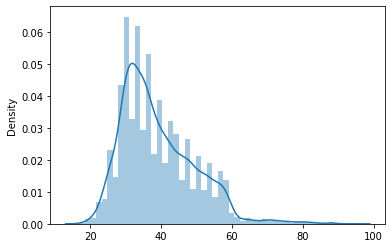

In [40]:
# yaş için dağılım grafiği
# scatter chart for age

sns.distplot(x=df.AGE);

In [46]:
col

['JOB',
 'MARITAL_STATUS',
 'EDUCATION',
 'DEFAULT_CREDIT',
 'HOUSING_LOAN',
 'PERSONAL_LOAN',
 'SUBSCRIBED']

In [47]:
# categorical list
cat_list=col

## Data Visualize;


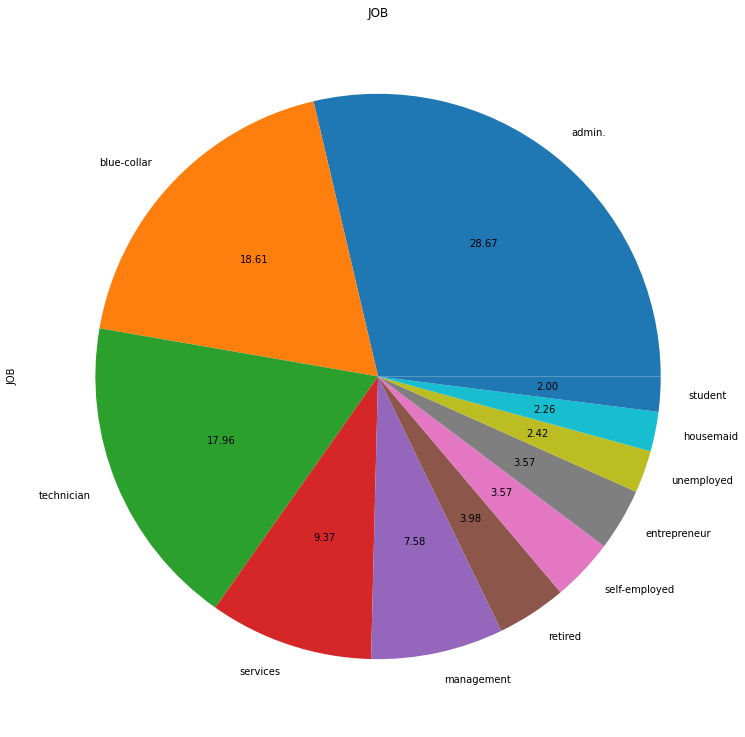

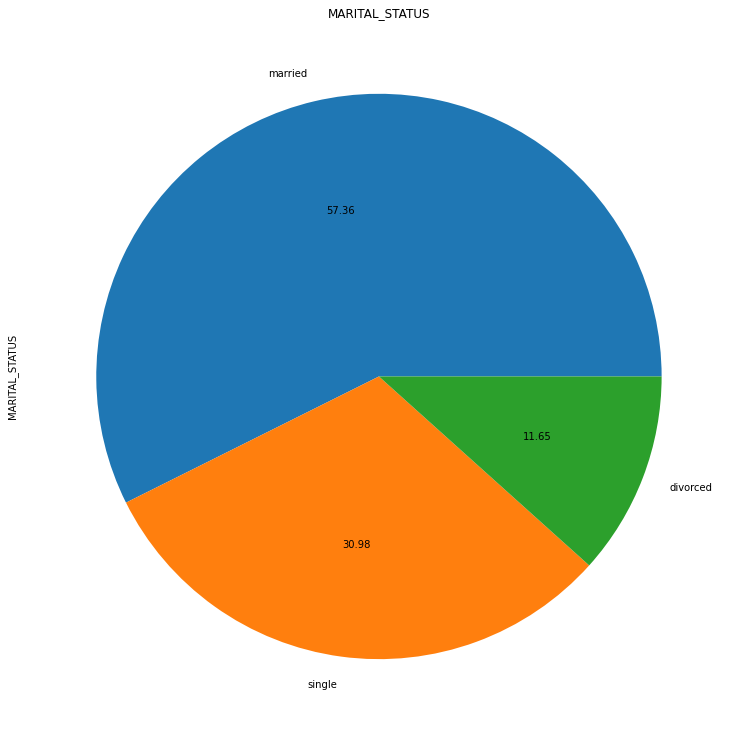

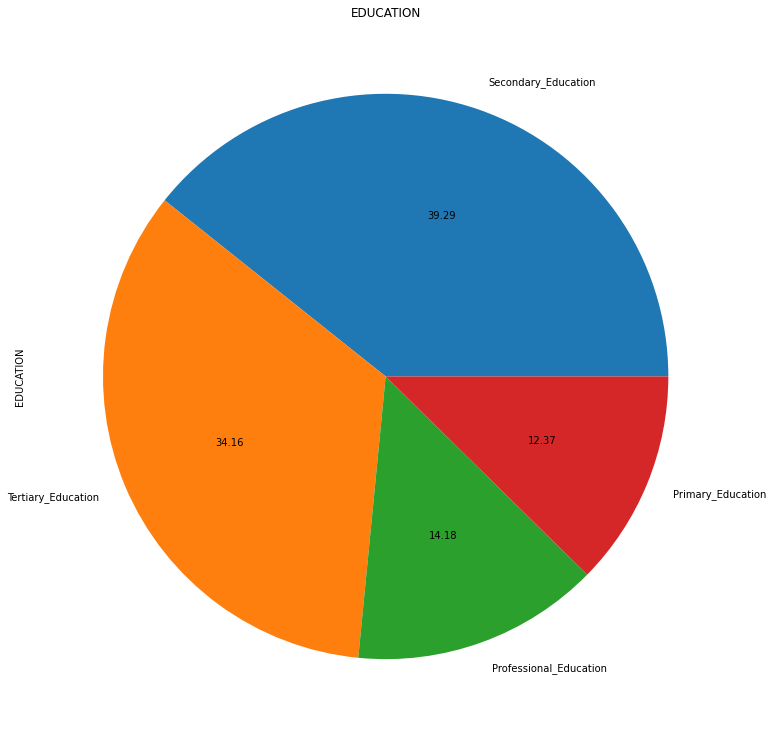

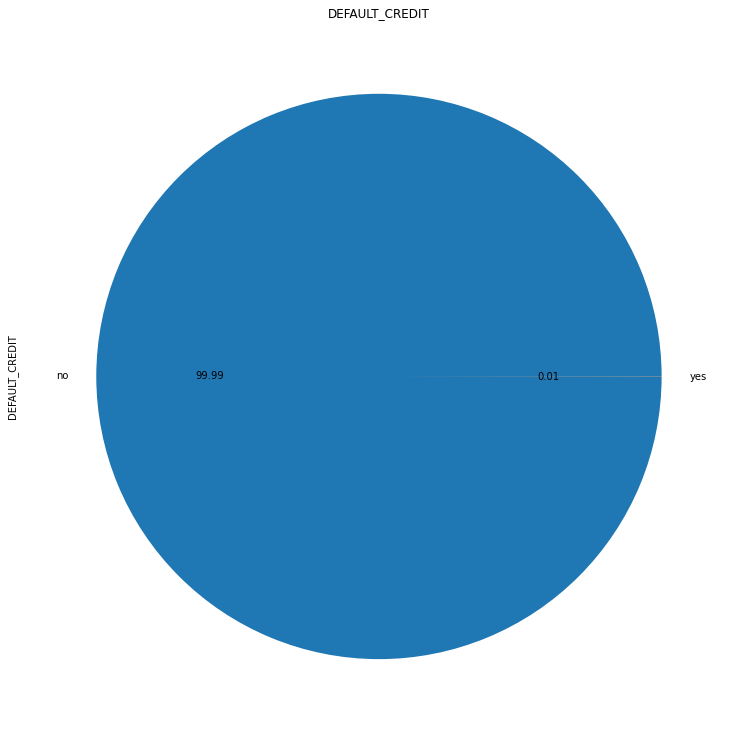

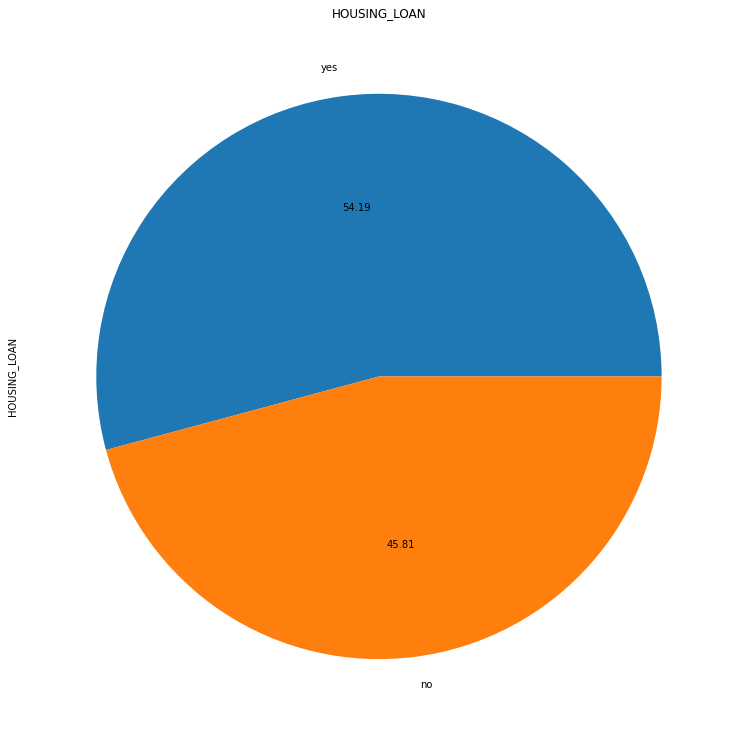

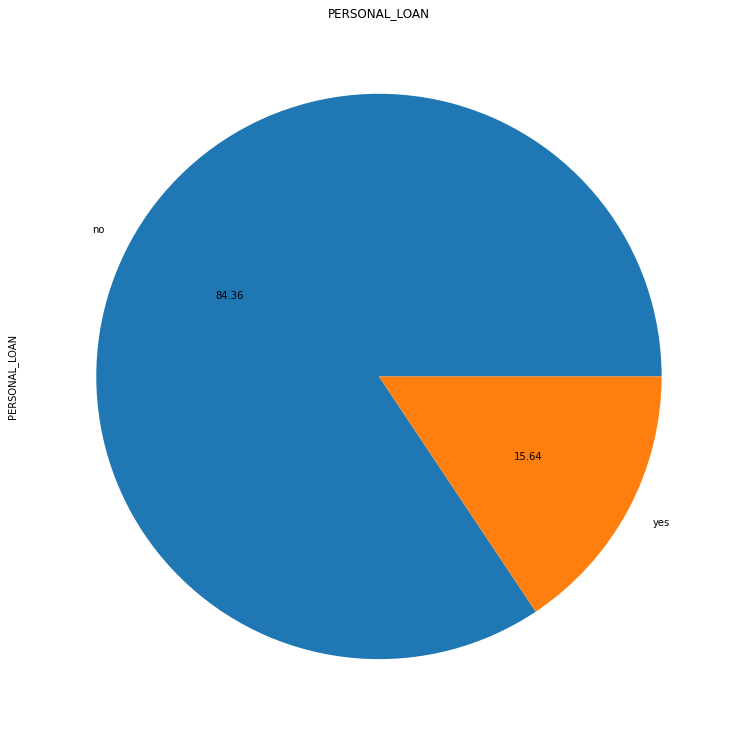

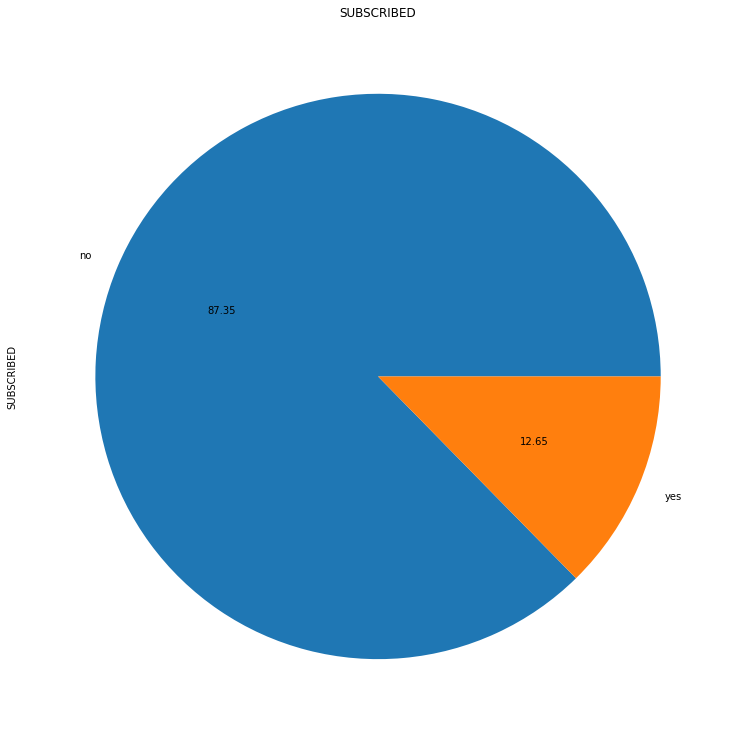

In [49]:
# categorical Analysis

for i in cat_list:
    
    plt.figure(figsize=(13,13))
    df[i].value_counts().plot(kind="pie",autopct="%.2f")
    plt.title(i)

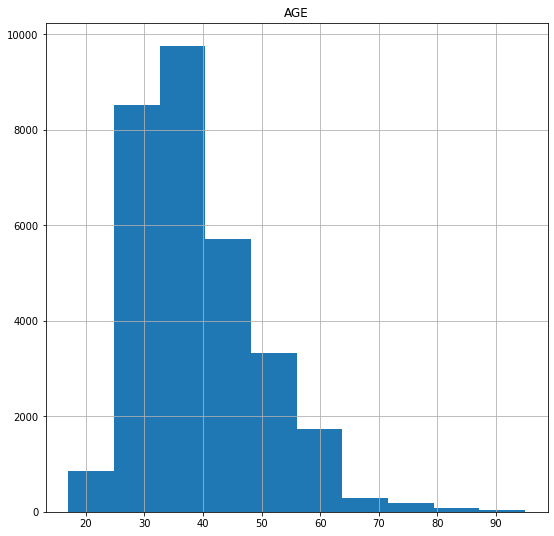

In [50]:
# histogram
df.hist(figsize=(9,9));

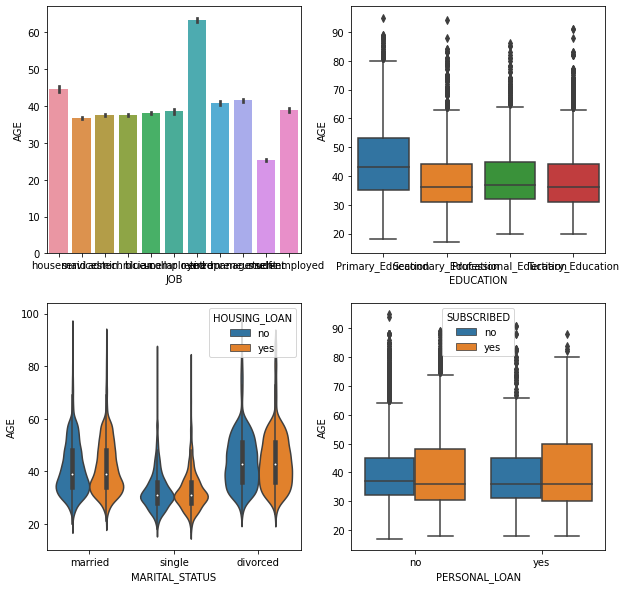

In [54]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
sns.barplot(x ='JOB',y ='AGE',data = df)
plt.subplot(2,2,2)
sns.boxplot(x="EDUCATION",y="AGE",data=df)
plt.subplot(2,2,3)
sns.violinplot(x="MARITAL_STATUS",y="AGE",hue="HOUSING_LOAN",data=df)
plt.subplot(2,2,4)
sns.boxplot(x="PERSONAL_LOAN",y="AGE",hue="SUBSCRIBED",data=df)
plt.show()

In [55]:
df.head()

,AGE,JOB,MARITAL_STATUS,EDUCATION,DEFAULT_CREDIT,HOUSING_LOAN,PERSONAL_LOAN,SUBSCRIBED
0,56,housemaid,married,Primary_Education,no,no,no,no
1,37,services,married,Secondary_Education,no,yes,no,no
2,40,admin.,married,Primary_Education,no,no,no,no
3,56,services,married,Secondary_Education,no,no,yes,no
4,59,admin.,married,Professional_Education,no,no,no,no


### ENCODİNG

In [56]:
from sklearn.preprocessing import LabelEncoder

In [57]:
le=LabelEncoder()

In [58]:
df["EDUCATION"]=le.fit_transform(df["EDUCATION"])
df

,AGE,JOB,MARITAL_STATUS,EDUCATION,DEFAULT_CREDIT,HOUSING_LOAN,PERSONAL_LOAN,SUBSCRIBED
0,56,housemaid,married,0,no,no,no,no
1,37,services,married,2,no,yes,no,no
2,40,admin.,married,0,no,no,no,no
3,56,services,married,2,no,no,yes,no
4,59,admin.,married,1,no,no,no,no
...,...,...,...,...,...,...,...,...
30472,73,retired,married,1,no,yes,no,yes
30473,46,blue-collar,married,1,no,no,no,no
30474,56,retired,married,3,no,yes,no,no
30475,44,technician,married,1,no,no,no,yes


In [59]:
# one-hot encoding

In [60]:
dms=pd.get_dummies(df[["JOB","MARITAL_STATUS","DEFAULT_CREDIT","HOUSING_LOAN",
                       "PERSONAL_LOAN","SUBSCRIBED"]])
dms

,JOB_admin.,JOB_blue-collar,JOB_entrepreneur,JOB_housemaid,JOB_management,JOB_retired,JOB_self-employed,JOB_services,JOB_student,JOB_technician,...,MARITAL_STATUS_married,MARITAL_STATUS_single,DEFAULT_CREDIT_no,DEFAULT_CREDIT_yes,HOUSING_LOAN_no,HOUSING_LOAN_yes,PERSONAL_LOAN_no,PERSONAL_LOAN_yes,SUBSCRIBED_no,SUBSCRIBED_yes
0,0,0,0,1,0,0,0,0,0,0,...,1,0,1,0,1,0,1,0,1,0
1,0,0,0,0,0,0,0,1,0,0,...,1,0,1,0,0,1,1,0,1,0
2,1,0,0,0,0,0,0,0,0,0,...,1,0,1,0,1,0,1,0,1,0
3,0,0,0,0,0,0,0,1,0,0,...,1,0,1,0,1,0,0,1,1,0
4,1,0,0,0,0,0,0,0,0,0,...,1,0,1,0,1,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30472,0,0,0,0,0,1,0,0,0,0,...,1,0,1,0,0,1,1,0,0,1
30473,0,1,0,0,0,0,0,0,0,0,...,1,0,1,0,1,0,1,0,1,0
30474,0,0,0,0,0,1,0,0,0,0,...,1,0,1,0,0,1,1,0,1,0
30475,0,0,0,0,0,0,0,0,0,1,...,1,0,1,0,1,0,1,0,0,1


In [61]:
df.drop(["JOB","MARITAL_STATUS","DEFAULT_CREDIT","HOUSING_LOAN",
        "PERSONAL_LOAN","SUBSCRIBED"],axis=1,inplace=True)
df=pd.concat([df,dms],axis=1)

In [62]:
df.head()

,AGE,EDUCATION,JOB_admin.,JOB_blue-collar,JOB_entrepreneur,JOB_housemaid,JOB_management,JOB_retired,JOB_self-employed,JOB_services,...,MARITAL_STATUS_married,MARITAL_STATUS_single,DEFAULT_CREDIT_no,DEFAULT_CREDIT_yes,HOUSING_LOAN_no,HOUSING_LOAN_yes,PERSONAL_LOAN_no,PERSONAL_LOAN_yes,SUBSCRIBED_no,SUBSCRIBED_yes
0,56,0,0,0,0,1,0,0,0,0,...,1,0,1,0,1,0,1,0,1,0
1,37,2,0,0,0,0,0,0,0,1,...,1,0,1,0,0,1,1,0,1,0
2,40,0,1,0,0,0,0,0,0,0,...,1,0,1,0,1,0,1,0,1,0
3,56,2,0,0,0,0,0,0,0,1,...,1,0,1,0,1,0,0,1,1,0
4,59,1,1,0,0,0,0,0,0,0,...,1,0,1,0,1,0,1,0,1,0


## Corelation Analysis

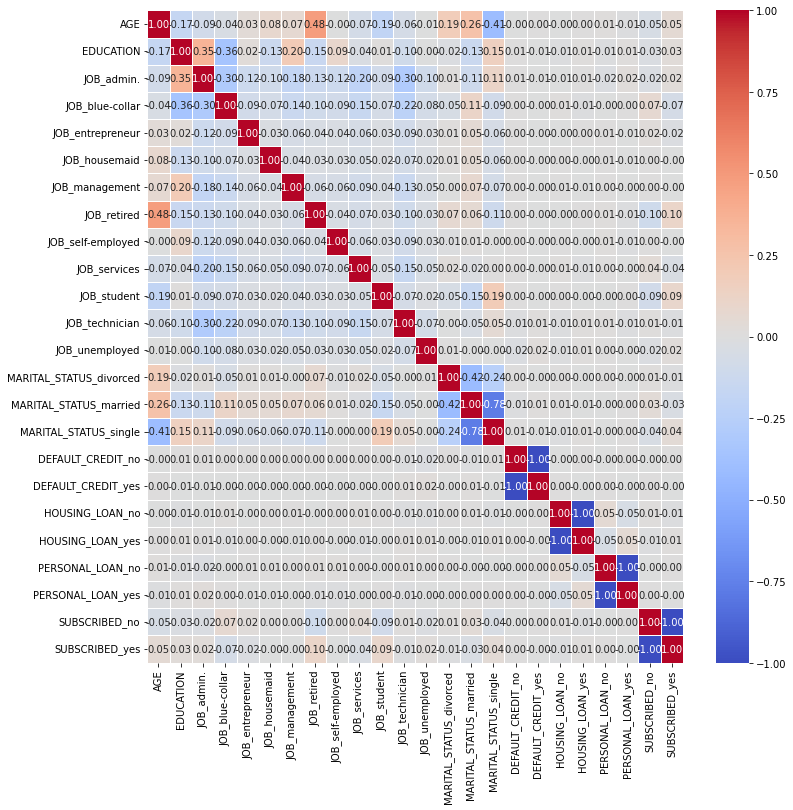

In [63]:
plt.figure(figsize=(12,12))
sns.heatmap(df.corr(),annot=True,linewidths=0.6,fmt=".2f",cmap="coolwarm")
plt.show()

In [65]:
df.columns

Index(['AGE', 'EDUCATION', 'JOB_admin.', 'JOB_blue-collar', 'JOB_entrepreneur',
       'JOB_housemaid', 'JOB_management', 'JOB_retired', 'JOB_self-employed',
       'JOB_services', 'JOB_student', 'JOB_technician', 'JOB_unemployed',
       'MARITAL_STATUS_divorced', 'MARITAL_STATUS_married',
       'MARITAL_STATUS_single', 'DEFAULT_CREDIT_no', 'DEFAULT_CREDIT_yes',
       'HOUSING_LOAN_no', 'HOUSING_LOAN_yes', 'PERSONAL_LOAN_no',
       'PERSONAL_LOAN_yes', 'SUBSCRIBED_no', 'SUBSCRIBED_yes'],
      dtype='object')

In [64]:
# delete the ones with high correlation
# korelasyon ları yüksek olanları silelim

In [67]:
df.drop(["DEFAULT_CREDIT_no","HOUSING_LOAN_yes","PERSONAL_LOAN_no",
        "SUBSCRIBED_no"],axis=1,inplace=True)
df.head()

,AGE,EDUCATION,JOB_admin.,JOB_blue-collar,JOB_entrepreneur,JOB_housemaid,JOB_management,JOB_retired,JOB_self-employed,JOB_services,JOB_student,JOB_technician,JOB_unemployed,MARITAL_STATUS_divorced,MARITAL_STATUS_married,MARITAL_STATUS_single,DEFAULT_CREDIT_yes,HOUSING_LOAN_no,PERSONAL_LOAN_yes,SUBSCRIBED_yes
0,56,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0
1,37,2,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0
2,40,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0
3,56,2,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0
4,59,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0


<a id="5"></a>
## 5.K-Means

In [69]:
# 2 farklı yakklaşım kullanalım(standartlaştırma ve normal veri)
# Let's use 2 different approaches (standardization and normal data)

In [70]:
kmeans=KMeans().fit(df)  #model

In [71]:
#optimum cluster;

score=[]
K=range(1,10)

for i in K:
    kmeans=KMeans(n_clusters=i,init="k-means++",random_state=0)
    kmeans.fit(df)
    score.append(kmeans.inertia_)

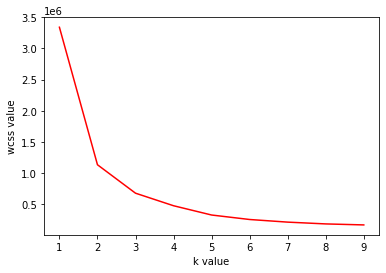

In [74]:
#visualize;

plt.plot(K,score,color="red")
plt.xlabel("k value")
plt.ylabel("wcss value")
plt.show()

In [75]:
#optimum number of clusters can be selected as 3, let's observe with yellowbrick
#optimum küme sayısı 3 olarak seçilebilir,yellowbrick ile gözlemleyelim

In [76]:
!pip install yellowbrick


In [77]:
from yellowbrick.cluster import KElbowVisualizer

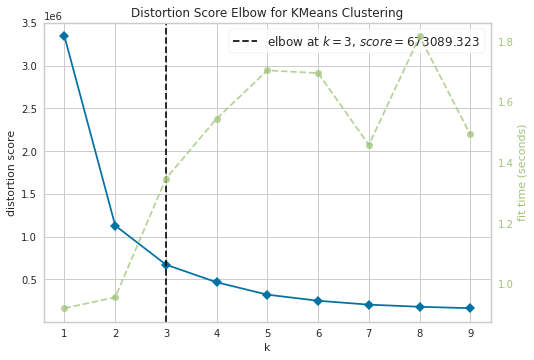

In [78]:
kmeans=KMeans()
visualizer=KElbowVisualizer(kmeans,k=(1,10))
visualizer.fit(df)
visualizer.poof()
plt.show()

In [80]:
# we can choose the number of clusters as 3
#küme sayısını 3 olarak seçebiliriz

In [79]:
# let's observe by standardizing
# standartlaştırarak gözlemleyelim

In [81]:
sc=StandardScaler()
X_std=sc.fit_transform(df)

/opt/conda/lib/python3.7/site-packages/yellowbrick/utils/kneed.py:156: YellowbrickWarning: No 'knee' or 'elbow point' detected This could be due to bad clustering, no actual clusters being formed etc.
  warnings.warn(warning_message, YellowbrickWarning)
/opt/conda/lib/python3.7/site-packages/yellowbrick/cluster/elbow.py:374: YellowbrickWarning: No 'knee' or 'elbow' point detected, pass `locate_elbow=False` to remove the warning
  warnings.warn(warning_message, YellowbrickWarning)


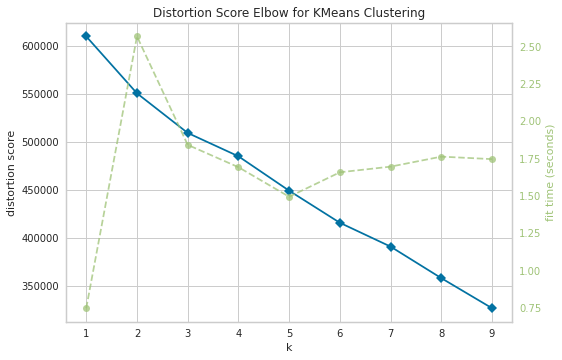

In [82]:
kmeans=KMeans()
visualizer=KElbowVisualizer(kmeans,k=(1,10))
visualizer.fit(X_std)
visualizer.poof()
plt.show()

In [83]:
# let's go over the data in the first case (k=3)
# ilk durumdaki veri üzerinden gidelim (k=3)

In [84]:
#final model;
kmeans=KMeans(n_clusters=3,init="k-means++").fit(df)

In [85]:
#add tag values;
cluster=kmeans.labels_

In [86]:
df["cluster_no"]=cluster

df.head()

,AGE,EDUCATION,JOB_admin.,JOB_blue-collar,JOB_entrepreneur,JOB_housemaid,JOB_management,JOB_retired,JOB_self-employed,JOB_services,...,JOB_technician,JOB_unemployed,MARITAL_STATUS_divorced,MARITAL_STATUS_married,MARITAL_STATUS_single,DEFAULT_CREDIT_yes,HOUSING_LOAN_no,PERSONAL_LOAN_yes,SUBSCRIBED_yes,cluster_no
0,56,0,0,0,0,1,0,0,0,0,...,0,0,0,1,0,0,1,0,0,2
1,37,2,0,0,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0
2,40,0,1,0,0,0,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
3,56,2,0,0,0,0,0,0,0,1,...,0,0,0,1,0,0,1,1,0,2
4,59,1,1,0,0,0,0,0,0,0,...,0,0,0,1,0,0,1,0,0,2


In [87]:
# We have done our clustering, now let's observe how many elements are in each cluster
# kümeleme işlemimizi yapmış olduk,şimdi her kümede kaç eleman var gözlemleyelim

df.cluster_no.value_counts()

1    13724
0    11112
2     5641
Name: cluster_no, dtype: int64

In [88]:
# her bir kümedeki eleman sayısını gözlemlemiş olduk
# we have observed the number of elements in each set

<a id="6"></a>
## 6.Hierarcihal Cluster

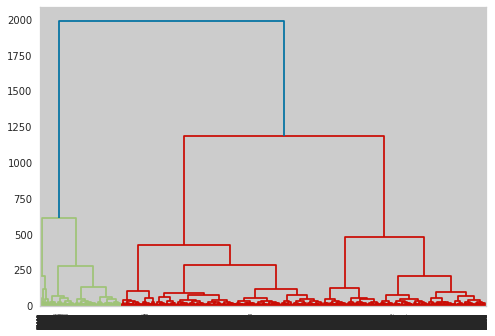

In [89]:
dendogram=sch.dendrogram(sch.linkage(df,method="ward"))

In [90]:
# görüldüğü gibi 1250 noktasında 3 küme ideal görünüyor
# as seen 3 clusters at point 1250 looks ideal

<a id="7"></a>

## 7.BIRCH Cluster


In [91]:
from sklearn.cluster import Birch


In [92]:
birch=Birch(n_clusters=3,threshold=1).fit(df) # model fit


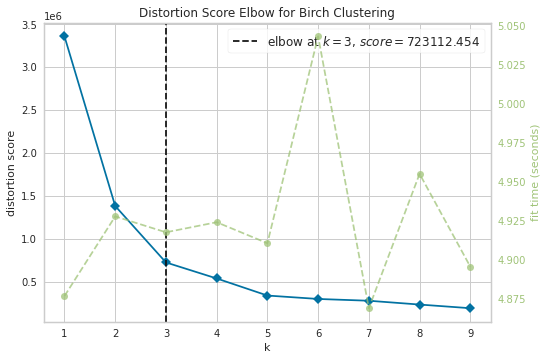

In [94]:
birch_cluster=Birch()
visualizer=KElbowVisualizer(birch_cluster,k=(1,10))
visualizer.fit(df)
visualizer.poof()
plt.show()

In [95]:
#gave the number of clusters 3...

In [96]:
pred=birch.predict(df)
pred

array([0, 1, 0, ..., 0, 0, 2])

<a id="8"></a>

## 8.Conclusion


* Using the Bank telemarketing dataset, we performed clustering operations according to the telemarketing status of a bank, and divided them into various clusters according to the behavior of the customers.

* Bank telemarketing verisetini kullanarak ,bir bankanın telefonla pazarlama durumuna göre kümeleme işlemleri gerçekleştirdik,Müşterilerin davranışlarına göre çşitli kümelere ayırdık.